# Entry clock vs leaky reward count (M5 test brought forward)

Loads and plots only. Numbers come from `run_event_kernels.py`:
- `--leaky`: one job per recday, >= 5 trials, anchor `entry`, `kin='strict'`;
- `--leaky --merge`;
- the planted-unit gate `--gate-leaky`.

Write-up: `code/EVENT_KERNELS.md`, entry "entry clock vs leaky reward count".

- **The test** (M5's reset-vs-superposition, brought forward). For every entry-locked unit, and 10
  non-locked units per recday, `stage2_unit` on the entry block compares two shapes:
  - the entry ramp exp(-t/tau), a reset at recording start;
  - a leaky reward count, the sum over rewards of exp(-(t - t_k)/tau): a superposition, i.e.
    integrated experience.
- Each gets its own tau, chosen on training sessions. Scoring is held-out Poisson deviance.
- A joint refit of both gives each family's unique gain beyond the other.
- **Separability** comes from behaviour: the count is flat before the first reward and follows
  reward rate, while the ramp follows time. The gate measures how well that works on real reward
  timing.


In [1]:
RUN_MODE = 'load'   # never computes; rerun the sbatch jobs and merges instead
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import event_kernels_plots as P
%matplotlib inline
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
FIG = os.path.join(P.REPO, 'data', 'figures', 'event_kernels', 'M5_leaky')
fig_path = lambda name: os.path.join(FIG, name)
L = {'LEC': P.load_latest(os.path.join(P.LEAKY_DIR, 'leaky_lec_kin-strict_mt5_np100')),
     'PFC': P.load_latest(os.path.join(P.LEAKY_DIR, 'leaky_pfc_kin-strict_mt5_np100'))}
for ds, m in L.items():
    print(ds, os.path.basename(m['_path']))

LEC leaky_lec_kin-strict_mt5_np100.pkl
PFC leaky_pfc_kin-strict_mt5_np100.pkl


## The gate: planted ramps and counts on the gate recday's real behaviour

In [2]:
for ds in L:
    g = P.latest_leaky_gate(ds)
    g['own_family_wins'] = np.where(g['kind'] == 'leaky_count', g['count_better'], ~g['count_better'].astype(bool))
    print(ds)
    print(g[g['kind'] != 'noise'].groupby(['kind', 'tau'])['own_family_wins'].mean().unstack().round(2).to_string())
    print('noise: count beats ramp in', round(float(g[g['kind'] == 'noise']['count_better'].mean()), 2))

LEC
tau          120.0   300.0   600.0   1200.0
kind                                       
entry_ramp      1.0     1.0     1.0    0.75
leaky_count     1.0     1.0     1.0    1.00
noise: count beats ramp in 0.55
PFC
tau          120.0   300.0   600.0   1200.0
kind                                       
entry_ramp      1.0     1.0     1.0     1.0
leaky_count     1.0     1.0     1.0     1.0
noise: count beats ramp in 0.55


## Same outputs as Stage 2 (equivalence, relative)

In [3]:
pd.concat({ds: m['stage2_equivalence'] for ds, m in L.items()})

column  units  nan_patterns_equal  max_rel_diff
LEC 0     dev_null   1222                True  4.308556e-15
    1       dev_np   1222                True  1.417235e-15
    2     dev_ramp   1222                True  3.461335e-15
    3     dev_bump   1222                True  1.930241e-15
    4   tau_median   1222                True  0.000000e+00
    5  peak_median   1222                True  0.000000e+00
    6        shape   1222                True  0.000000e+00
PFC 0     dev_null    633                True  2.697305e-14
    1       dev_np    633                True  2.814838e-14
    2     dev_ramp    633                True  2.751002e-14
    3     dev_bump    633                True  2.666223e-14
    4   tau_median    633                True  0.000000e+00
    5  peak_median    633                True  0.000000e+00
    6        shape    633                True  0.000000e+00

## Collinearity of the ramp and the count per recday (block level, within-session centred)

In [4]:
pd.concat({ds: m['summary'][['recday', 'n_units', 'r_ramp_count_300s', 'r_ramp_count_1200s']].describe().round(3) for ds, m in L.items()})

n_units  r_ramp_count_300s  r_ramp_count_1200s
LEC count   25.000             25.000              25.000
    mean    48.880             -0.816              -0.905
    std     17.810              0.084               0.046
    min     24.000             -0.970              -0.988
    25%     35.000             -0.860              -0.948
    50%     45.000             -0.807              -0.891
    75%     62.000             -0.747              -0.876
    max     89.000             -0.658              -0.832
PFC count   25.000             24.000              24.000
    mean    25.320             -0.871              -0.939
    std     13.934              0.064               0.032
    min      0.000             -0.953              -0.989
    25%     14.000             -0.906              -0.960
    50%     26.000             -0.881              -0.940
    75%     38.000             -0.855              -0.928
    max     50.000             -0.651              -0.874

## F19. Which explains the entry kernel better

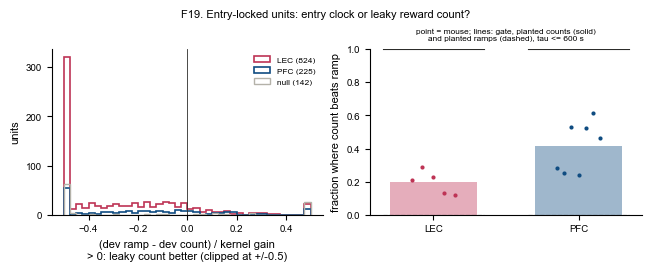

units  count_better  median_pref  ramp_like
dataset mouse                                             
LEC     ah08     214         0.215       -0.433      0.757
        ah10     327         0.275       -0.127      0.890
        ly05     133         0.218       -0.540      0.767
        ly06     123         0.130       -0.355      0.902
        ly07     175         0.120       -0.418      0.903
PFC     ab03      71         0.239       -0.198      0.732
        ah03       5         0.200       -0.562      0.800
        ah04     152         0.500       -0.003      0.474
        ah07      68         0.221       -0.306      0.632
        me08      24         0.500       -0.034      0.500
        me10      11         0.636        0.069      0.455
        me11      83         0.458       -0.019      0.446

In [5]:
P.plot_leaky_preference(L, out_path=fig_path('F19_leaky_preference')); plt.show()
t = P.table_leaky(L)
t[t['role'] == 'locked'].assign(v=lambda x: x['count_better'].astype(float)).groupby(['dataset', 'mouse']).agg(
    units=('v', 'size'), count_better=('v', 'mean'), median_pref=('pref', 'median'),
    ramp_like=('ramp_like', 'mean')).round(3)

In [6]:
t.groupby(['dataset', 'role', 'ramp_like']).agg(units=('pref', 'size'), count_better=('count_better', 'mean'),
    median_pref=('pref', 'median'), median_count_unique=('count_unique', 'median'),
    median_ramp_unique=('ramp_unique', 'median')).round(3)

units  count_better  median_pref  median_count_unique  median_ramp_unique
dataset role        ramp_like                                                                           
LEC     locked      False        148         0.554        0.098                0.050               0.034
                    True         824         0.146       -0.352               -0.004               0.337
        null_sample False        192         0.599        1.044                0.132              -0.940
                    True          58         0.138       -0.822               -0.025               0.828
PFC     locked      False        189         0.577        0.062                0.035              -0.031
                    True         225         0.253       -0.180               -0.003               0.169
        null_sample False        182         0.643        0.175                0.214              -0.091
                    True          37         0.351       -0.191               -0.028               0.120

## F20. Unique gains and matched time constants

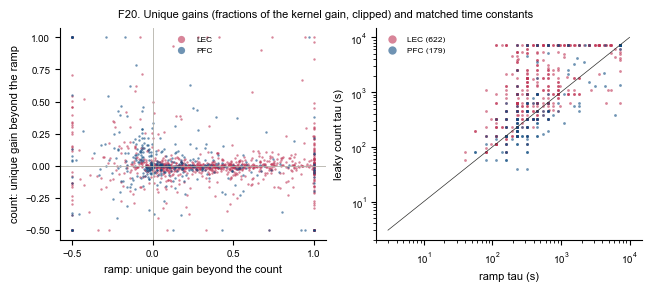

In [7]:
P.plot_leaky_unique(L, out_path=fig_path('F20_leaky_unique')); plt.show()

## F21. Gate envelope and collinearity

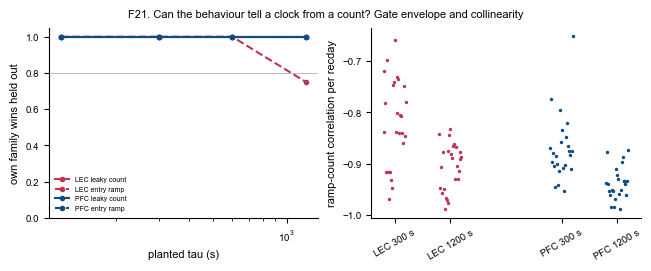

In [8]:
P.plot_leaky_gate(L, out_path=fig_path('F21_leaky_gate')); plt.show()